# Pipeline de análise — as letras de diferentes países estão ficando parecidas?

Entrada: `finalData.csv` (top 40 anual por país, com letra original, idioma e tradução `letra_en`). Se ele não existir, usa `completoComLetras.csv` + `letras_en.jsonl`.

Etapas (seguem a seção *Metodologia* da proposta):

1. Limpeza das letras, deduplicação dentro da célula e detecção de idioma
2. Embeddings multilíngues (LaBSE por padrão), com letras longas divididas em trechos e média dos vetores — **com cache em `dados/embeddings/`**
3. UMAP + K-Means (k por silhueta) e HDBSCAN para comparação
4. Interpretação dos clusters (c-TF-IDF, a mesma ideia do BERTopic) e diagnóstico de viés de idioma
5. Similaridade entre países: **1 − JS** (base 2) das distribuições sobre clusters e **cosseno entre centroides**; série $S_t$
6. Tendência: inclinação (regressão linear) + Spearman, IC 95% por **bootstrap** de músicas dentro das células; **teste de permutação** dos rótulos de país
7. Hipóteses H1 (EUA, BR, MX, ES convergem) e H2 (Japão se mantém distante)
8. Grafo de países + Louvain
9. Controles: músicas compartilhadas × exclusivas
10. Robustez: repete S_t, H1/H2 e o controle de exclusivas com as letras traduzidas para o inglês

Saídas em `resultados/` (CSVs e figuras). **Nenhuma letra é gravada nas saídas**, só vetores, rótulos e métricas.

Dependências: `pip install sentence-transformers umap-learn langdetect "scikit-learn>=1.3" networkx`

In [1]:
import os, re, hashlib, itertools, unicodedata, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr, linregress
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
import networkx as nx
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="umap")

# ---------- entradas / saídas ----------
ARQ_DADOS = Path("./finalData.csv") if Path("./finalData.csv").exists() else Path("./completoComLetras.csv")
ARQ_TRAD  = Path("./letras_en.jsonl")   # só usado se ARQ_DADOS não tiver a coluna letra_en
PASTA_EMB = Path("./dados/embeddings")   # só vetores (podem ser divulgados)
PASTA_RES = Path("./resultados")
PASTA_EMB.mkdir(parents=True, exist_ok=True)
PASTA_RES.mkdir(parents=True, exist_ok=True)

# ---------- parâmetros ----------
MODELO     = os.environ.get("MODELO_EMB", "sentence-transformers/LaBSE")  # alternativa: "intfloat/multilingual-e5-base"
BATCH      = 32
EXCLUIR    = []          # células (país, ano) a remover, ex.: [("jp", 2017)]
K_MIN, K_MAX = 5, 25     # faixa de k testada no K-Means
UMAP_DIM   = 10          # dimensões do UMAP usado para clusterizar
MIN_CELULA = 10          # mínimo de músicas para uma célula entrar nos controles
N_BOOT     = int(os.environ.get("N_BOOT", 1000))
N_PERM     = int(os.environ.get("N_PERM", 1000))
SEED       = 42

PAISES   = ["us", "br", "mx", "es", "au", "jp"]
NOMES    = {"us": "EUA", "br": "Brasil", "mx": "México", "es": "Espanha", "au": "Austrália", "jp": "Japão"}
GRUPO_H1 = ["us", "br", "mx", "es"]   # H1: convergência entre países ligados à indústria global
GRUPO_H2 = ["jp"]                     # H2: distância mantida

# ---------- estilo dos gráficos ----------
COR = {"s1": "#2a78d6", "s2": "#eb6834", "s3": "#1baf7a", "neutro": "#b9b8b3",
       "texto": "#0b0b0b", "texto2": "#52514e", "grade": "#e6e5e1", "fundo": "#fcfcfb"}
SEQ = LinearSegmentedColormap.from_list("seq_azul", ["#cde2fb", "#86b6ef", "#2a78d6", "#1c5cab", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])  # vermelho = afastando · azul = aproximando
plt.rcParams.update({
    "figure.facecolor": COR["fundo"], "axes.facecolor": COR["fundo"], "savefig.facecolor": COR["fundo"],
    "axes.edgecolor": COR["grade"], "axes.labelcolor": COR["texto2"], "text.color": COR["texto"],
    "xtick.color": COR["texto2"], "ytick.color": COR["texto2"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COR["grade"], "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "lines.markersize": 6, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})

## 1. Dados, limpeza e idioma

In [2]:
# timestamps/cabeçalhos de LRC ("[03:17.76]", "[ar:Artista]") e rótulos estruturais ("[Refrão]", "(Chorus)")
_LRC    = re.compile(r"^(?:\s*\[(?:\d{1,2}:\d{2}(?:[.:]\d{1,3})?|[a-z]{2,6}:[^\]\n]*)\])+[ \t]*", re.I | re.M)
_ROTULO = re.compile(r"^\s*[\[\(](?:refr[aã]o|chorus|pre-?chorus|verse|verso|coro|estribillo|bridge|ponte|puente|"
                     r"intro|outro|hook|interlude)[^\]\)\n]*[\]\)]\s*$", re.I | re.M)

def limpa_letra(t):
    if not isinstance(t, str):
        return ""
    t = _LRC.sub("", t)
    t = _ROTULO.sub("", t)
    t = re.sub(r"[ \t]+\n", "\n", t)
    t = re.sub(r"\n{3,}", "\n\n", t)
    return t.strip()

def _sem_acento(s):
    return "".join(c for c in unicodedata.normalize("NFKD", s) if not unicodedata.combining(c))

def chave_musica(title, artists):
    # identifica a mesma música com track_ids diferentes (remix, ao vivo, relançamento)
    t = _sem_acento(str(title).lower())
    t = re.sub(r"[\(\[].*?[\)\]]", " ", t)        # (feat. X), [Remix], (Ao Vivo)
    t = re.split(r"\s+-\s+", t)[0]                # "- Ao Vivo", "- Remix", "- From ..."
    t = re.sub(r"[^\w]+", " ", t).strip()
    a = re.split(r"\s*(?:\||,|&|\bfeat\.?|\bft\.?)\s*", _sem_acento(str(artists).lower()))[0]
    a = re.sub(r"[^\w]+", " ", a).strip()
    return f"{t}::{a}"

dados = pd.read_csv(ARQ_DADOS)
dados = dados[dados["cc"].isin(PAISES)].copy()
for cc, ano in EXCLUIR:
    dados = dados[~((dados["cc"] == cc) & (dados["year"] == ano))]

n_lrc = dados["letra"].fillna("").str.contains(_LRC).sum()
dados["letra_limpa"] = dados["letra"].map(limpa_letra)
dados["chave"] = [chave_musica(t, a) for t, a in zip(dados["title"], dados["artists"])]

antes = len(dados)
dados = (dados.sort_values("pontos", ascending=False)
              .drop_duplicates(["cc", "year", "chave"])            # mesma música 2x na mesma célula
              .sort_values(["cc", "year", "pontos"], ascending=[True, True, False]))
dup = antes - len(dados)
dados = dados[dados["letra_limpa"].str.len() >= 30]               # sem letra útil

print(f"linhas com resíduo de LRC limpas: {n_lrc} | duplicatas removidas dentro das células: {dup}")
print(f"{len(dados)} linhas (país × ano × música) | {dados['track_id'].nunique()} faixas únicas")
display(dados.groupby(["cc", "year"]).size().unstack())

linhas com resíduo de LRC limpas: 16 | duplicatas removidas dentro das células: 3
2156 linhas (país × ano × música) | 1444 faixas únicas


year,2017,2018,2019,2020,2021,2022,2023,2024,2025
cc,,,,,,,,,
au,40,40,40,40,40,40,40,40,40
br,39,39,40,40,40,40,40,40,40
es,40,40,40,40,40,40,40,40,40
jp,39,40,40,40,40,40,40,40,40
mx,40,40,40,40,40,40,40,40,40
us,40,40,40,40,39,40,40,40,40


In [3]:
_limpa_en = lambda t: limpa_letra(t) if isinstance(t, str) and t.strip() else np.nan
faixas = dados.drop_duplicates("track_id").set_index("track_id")
faixas = faixas[["title", "artists", "chave", "letra_limpa"] + [c for c in ["letra_en", "idioma"] if c in faixas.columns]].copy()
faixas = faixas.rename(columns={"idioma": "idioma_trad"})
dados = dados.drop(columns=[c for c in ["idioma", "letra_en"] if c in dados.columns])

# traduções (robustez): coluna letra_en do CSV; senão, letras_en.jsonl
if "letra_en" in faixas.columns:
    faixas["letra_en"] = faixas["letra_en"].map(_limpa_en)
    print(f"traduções lidas de {ARQ_DADOS}")
elif ARQ_TRAD.exists():
    tr = pd.read_json(ARQ_TRAD, lines=True).drop_duplicates("track_id").set_index("track_id")
    faixas["letra_en"] = tr["letra_en"].reindex(faixas.index).map(_limpa_en)
    faixas["idioma_trad"] = tr["idioma"].reindex(faixas.index)
else:
    faixas["letra_en"] = np.nan
if "idioma_trad" not in faixas.columns:
    faixas["idioma_trad"] = np.nan

# idioma
try:
    from langdetect import detect, DetectorFactory
    DetectorFactory.seed = 0
    def _detecta(t):
        try:
            return detect(t[:2000])
        except Exception:
            return None
    faixas["idioma"] = faixas["letra_limpa"].map(_detecta)
except ImportError:
    print("langdetect não instalado: usando o idioma que veio nos dados de tradução")
    faixas["idioma"] = faixas["idioma_trad"]
faixas["idioma"] = faixas["idioma"].where(faixas["idioma"].isin(["en", "es", "pt", "ja", "ko"]), "outro")

dados = dados.merge(faixas[["idioma"]], left_on="track_id", right_index=True, how="left")
print("idioma das faixas únicas:", faixas["idioma"].value_counts().to_dict())
print(f"faixas com tradução para o inglês: {faixas['letra_en'].notna().sum()} de {len(faixas)}")
print("\n% de músicas por idioma em cada país (todas as células somadas):")
display((pd.crosstab(dados["cc"], dados["idioma"], normalize="index") * 100).round(0))

traduções lidas de finalData.csv


idioma das faixas únicas: {'es': 494, 'en': 447, 'pt': 319, 'ja': 177, 'outro': 4, 'ko': 3}
faixas com tradução para o inglês: 1444 de 1444

% de músicas por idioma em cada país (todas as células somadas):


idioma,en,es,ja,ko,outro,pt
cc,,,,,,
au,100.0,0.0,0.0,0.0,0.0,0.0
br,6.0,1.0,0.0,0.0,0.0,92.0
es,7.0,92.0,0.0,0.0,0.0,0.0
jp,18.0,0.0,81.0,1.0,1.0,0.0
mx,8.0,92.0,0.0,0.0,0.0,0.0
us,97.0,3.0,0.0,0.0,0.0,0.0


## 2. Embeddings

Cada letra é dividida em trechos que cabem no limite de tokens do modelo (respeitando quebras de linha); os vetores dos trechos são normalizados, promediados e renormalizados.
O cache é indexado por `track_id` + hash do texto: se a letra mudar, só ela é recalculada. Em CPU, o LaBSE leva alguns minutos para as ~1.450 letras; em GPU, segundos.

In [4]:
_modelo = {}

def carrega_modelo():
    if "m" not in _modelo:
        import torch
        from sentence_transformers import SentenceTransformer
        from transformers.utils import logging as hf_logging
        hf_logging.set_verbosity_error()   # aviso de "sequence length" na contagem de tokens é inofensivo
        dev = "cuda" if torch.cuda.is_available() else "cpu"
        _modelo["m"] = SentenceTransformer(MODELO, device=dev)
        print(f"modelo {MODELO} em {dev} | max_seq_length = {_modelo['m'].max_seq_length}")
    return _modelo["m"]

def divide_trechos(texto, tok, max_tok):
    linhas = [l for l in texto.split("\n") if l.strip()]
    trechos, atual, n = [], [], 0
    for l in linhas:
        k = len(tok.tokenize(l)) + 1
        if atual and n + k > max_tok:
            trechos.append("\n".join(atual))
            atual, n = [], 0
        atual.append(l)
        n += k
    if atual:
        trechos.append("\n".join(atual))
    return trechos or [texto]

def _slug(s):
    return re.sub(r"[^\w]+", "_", s).strip("_")

def gera_embeddings(textos: pd.Series, nome: str) -> np.ndarray:
    # textos: Series indexada por track_id. Retorna matriz (n, d) na mesma ordem, linhas com norma 1.
    arq = PASTA_EMB / f"{_slug(MODELO)}__{nome}.npz"
    chaves = [f"{tid}:{hashlib.md5(t.encode('utf-8')).hexdigest()[:10]}" for tid, t in textos.items()]
    cache = {}
    if arq.exists():
        z = np.load(arq)
        cache = dict(zip(z["chaves"].tolist(), z["emb"]))
    falta = [(c, t) for c, t in zip(chaves, textos.values) if c not in cache]
    if falta:
        m = carrega_modelo()
        max_tok = m.max_seq_length - 8
        pref = "passage: " if "e5" in MODELO.lower() else ""
        pedacos, dono = [], []
        for c, t in falta:
            for b in divide_trechos(t, m.tokenizer, max_tok):
                pedacos.append(pref + b)
                dono.append(c)
        print(f"[{nome}] codificando {len(falta)} letras em {len(pedacos)} trechos...")
        V = m.encode(pedacos, batch_size=BATCH, normalize_embeddings=True, show_progress_bar=True, convert_to_numpy=True)
        dono = np.array(dono)
        for c, _ in falta:
            v = V[dono == c].mean(axis=0)
            cache[c] = v / np.linalg.norm(v)
        ks = list(cache)
        np.savez_compressed(arq, chaves=np.array(ks), emb=np.stack([cache[k] for k in ks]).astype(np.float32))
    else:
        print(f"[{nome}] {len(chaves)} embeddings lidos do cache {arq}")
    return np.stack([cache[c] for c in chaves]).astype(np.float32)

E_orig = gera_embeddings(faixas["letra_limpa"], "original")
POS = {t: i for i, t in enumerate(faixas.index)}   # track_id -> linha da matriz
print("matriz de embeddings:", E_orig.shape)

[original] 1444 embeddings lidos do cache dados/embeddings/sentence_transformers_LaBSE__original.npz
matriz de embeddings: (1444, 768)


## 3. Funções de análise

In [5]:
def reduz_e_agrupa(E):
    # UMAP (cosseno) -> K-Means com k escolhido por silhueta; HDBSCAN para comparação.
    import umap
    Z = umap.UMAP(n_components=UMAP_DIM, n_neighbors=15, min_dist=0.0, metric="cosine",
                  random_state=SEED).fit_transform(E)
    sil = {}
    for k in range(K_MIN, K_MAX + 1):
        sil[k] = silhouette_score(Z, KMeans(k, n_init=10, random_state=SEED).fit_predict(Z))
    sil = pd.Series(sil)
    k = int(sil.idxmax())
    labels = KMeans(k, n_init=10, random_state=SEED).fit_predict(Z)
    try:
        from sklearn.cluster import HDBSCAN
    except ImportError:
        from hdbscan import HDBSCAN
    hl = HDBSCAN(min_cluster_size=10).fit_predict(Z)
    ok = hl >= 0
    info = {"k": k, "silhueta": round(float(sil[k]), 3),
            "hdbscan_clusters": int(len(set(hl[ok]))), "hdbscan_ruido": round(float(1 - ok.mean()), 3),
            "ARI_kmeans_vs_hdbscan": round(float(adjusted_rand_score(labels[ok], hl[ok])), 3) if ok.any() else np.nan}
    return Z, labels, sil, info

def js_div(P, Q):
    # divergência de Jensen-Shannon em base 2 (em [0, 1]), vetorizada nas linhas.
    # Igual a scipy.spatial.distance.jensenshannon(P, Q, base=2) ** 2 (o scipy devolve a *distância*, a raiz).
    M = (P + Q) / 2
    with np.errstate(divide="ignore", invalid="ignore"):
        a = np.where(P > 0, P * np.log2(P / M), 0.0).sum(-1)
        b = np.where(Q > 0, Q * np.log2(Q / M), 0.0).sum(-1)
    return (a + b) / 2

def monta_celulas(d, pos):
    return {(cc, ano): g["track_id"].map(pos).to_numpy() for (cc, ano), g in d.groupby(["cc", "year"])}

def prepara_pares(chaves):
    ix = {c: i for i, c in enumerate(chaves)}
    I, J, anos, A, B = [], [], [], [], []
    for ano in sorted({a for _, a in chaves}):
        ps = sorted((cc for cc, a in chaves if a == ano), key=PAISES.index)
        for a, b in itertools.combinations(ps, 2):
            I.append(ix[(a, ano)]); J.append(ix[(b, ano)]); anos.append(ano); A.append(a); B.append(b)
    return {"I": np.array(I), "J": np.array(J), "ano": np.array(anos), "a": np.array(A), "b": np.array(B)}

def _sims(cel_idx, labels, E, k, pr):
    P = np.stack([np.bincount(labels[ix], minlength=k) / len(ix) for ix in cel_idx])
    Cn = np.stack([E[ix].mean(0) for ix in cel_idx])
    Cn /= np.linalg.norm(Cn, axis=1, keepdims=True)
    return 1 - js_div(P[pr["I"]], P[pr["J"]]), (Cn[pr["I"]] * Cn[pr["J"]]).sum(1)

def serie_similaridade(d, pos, labels, E, k, n_boot=N_BOOT):
    # similaridades observadas por par de países e ano + réplicas bootstrap (reamostra músicas dentro de cada célula).
    cel = monta_celulas(d, pos)
    chaves = list(cel)
    pr = prepara_pares(chaves)
    idx = [cel[c] for c in chaves]
    sj, sc = _sims(idx, labels, E, k, pr)
    rng = np.random.default_rng(SEED)
    Bj = np.empty((n_boot, len(sj))); Bc = np.empty((n_boot, len(sc)))
    for r in range(n_boot):
        Bj[r], Bc[r] = _sims([rng.choice(ix, len(ix), replace=True) for ix in idx], labels, E, k, pr)
    pares_df = pd.DataFrame({"ano": pr["ano"], "a": pr["a"], "b": pr["b"], "sim_js": sj, "sim_cos": sc})
    return {"pr": pr, "sj": sj, "sc": sc, "Bj": Bj, "Bc": Bc, "anos": np.unique(pr["ano"]), "pares_df": pares_df}

def resumo(res, mascara=None):
    # média por ano sobre os pares selecionados (S_t), IC 95% bootstrap e tendência.
    pr, anos = res["pr"], res["anos"]
    m = np.ones(len(pr["I"]), bool) if mascara is None else mascara
    W = np.zeros((len(m), len(anos)))
    for t, ano in enumerate(anos):
        sel = m & (pr["ano"] == ano)
        if sel.any():
            W[sel, t] = 1 / sel.sum()
    v = W.sum(0) > 0
    x = anos[v].astype(float); xc = x - x.mean()
    out, tend = {"ano": anos[v]}, {}
    for met, obs, B in [("js", res["sj"], res["Bj"]), ("cos", res["sc"], res["Bc"])]:
        o, b = (obs @ W)[v], (B @ W)[:, v]
        # reamostrar com reposição deixa as células mais ruidosas e puxa a similaridade para baixo;
        # o IC é centrado no valor observado: [obs - (média_boot - q2.5), obs + (q97.5 - média_boot)]
        q_lo, q_hi = np.percentile(b, [2.5, 97.5], axis=0)
        out[met] = o
        out[f"{met}_lo"], out[f"{met}_hi"] = o - (b.mean(0) - q_lo), o + (q_hi - b.mean(0))
        inc = (o - o.mean()) @ xc / (xc @ xc)
        inc_b = (b - b.mean(1, keepdims=True)) @ xc / (xc @ xc)
        lo, hi = inc - (inc_b.mean() - np.percentile(inc_b, 2.5)), inc + (np.percentile(inc_b, 97.5) - inc_b.mean())
        rho, p = spearmanr(x, o)
        p_ols = linregress(x, o).pvalue if len(x) > 2 else np.nan
        # o bootstrap mede o ruído dentro das células; a regressão mede se a reta explica a variação entre anos.
        # Só chamamos de tendência quando os dois concordam.
        sinal = "convergência" if lo > 0 else ("divergência" if hi < 0 else None)
        leitura = "sem tendência clara" if sinal is None else (sinal if p_ols < 0.05 else f"{sinal} fraca (só no bootstrap)")
        tend[met] = {"inclinacao_por_ano": inc, "ic95_lo": lo, "ic95_hi": hi, "p_regressao": p_ols,
                     "spearman_rho": rho, "spearman_p": p, "leitura": leitura}
    return pd.DataFrame(out), tend

def mascara_pares(res, grupo_a, grupo_b=None):
    # pares dentro de grupo_a (grupo_b=None) ou entre grupo_a e grupo_b.
    a, b = res["pr"]["a"], res["pr"]["b"]
    if grupo_b is None:
        return np.isin(a, grupo_a) & np.isin(b, grupo_a)
    return (np.isin(a, grupo_a) & np.isin(b, grupo_b)) | (np.isin(b, grupo_a) & np.isin(a, grupo_b))

def S_ano(idx, ccs, labels, E, k):
    paises = np.unique(ccs)
    P = np.stack([np.bincount(labels[idx[ccs == c]], minlength=k) / (ccs == c).sum() for c in paises])
    Cn = np.stack([E[idx[ccs == c]].mean(0) for c in paises])
    Cn /= np.linalg.norm(Cn, axis=1, keepdims=True)
    I, J = np.triu_indices(len(paises), 1)
    return (1 - js_div(P[I], P[J])).mean(), (Cn[I] * Cn[J]).sum(1).mean()

def permutacao(d, pos, labels, E, k, n_perm=N_PERM):
    # H0: o país não importa. Embaralha os rótulos de país entre as músicas do ano (tamanhos das células mantidos).
    # p pequeno => países mais diferentes entre si do que o acaso. S_rel = S_obs / S_nulo (1 = indistinguível do acaso).
    rng = np.random.default_rng(SEED)
    linhas = []
    for ano, g in d.groupby("year"):
        idx, ccs = g["track_id"].map(pos).to_numpy(), g["cc"].to_numpy()
        oj, oc = S_ano(idx, ccs, labels, E, k)
        nul = np.array([S_ano(idx, rng.permutation(ccs), labels, E, k) for _ in range(n_perm)])
        linhas.append({"ano": ano, "S_js": oj, "S_js_nulo": nul[:, 0].mean(), "S_js_rel": oj / nul[:, 0].mean(),
                       "p_js": (1 + (nul[:, 0] <= oj).sum()) / (1 + n_perm),
                       "S_cos": oc, "S_cos_nulo": nul[:, 1].mean(), "S_cos_rel": oc / nul[:, 1].mean(),
                       "p_cos": (1 + (nul[:, 1] <= oc).sum()) / (1 + n_perm)})
    return pd.DataFrame(linhas)

def tabela_tendencias(tends):
    linhas = []
    for nome, t in tends.items():
        for met, v in t.items():
            linhas.append({"serie": nome, "metrica": "1−JS" if met == "js" else "cosseno", **v})
    return pd.DataFrame(linhas).round(4)

def topicos_ctfidf(textos, labels, k, n=10):
    # c-TF-IDF (representação de tópicos do BERTopic): termos característicos de cada cluster.
    extra = ("que de la el en y a los las se no me te lo le mi tu un una por con para es del al como mas pero yo si ya "
             "eso esta este todo nada o e do da os as um uma com pra não nao eu você voce ele ela meu minha seu sua "
             "ta tá tô vai vou oh ah eh yeah yeh ey hey ooh uh na woah whoa ayy ay nah mmm hmm em ni dont im youre "
             "cause got gonna wanna let just like know").split()
    docs = pd.Series(textos).groupby(labels).apply(lambda s: " ".join(s)).reindex(range(k), fill_value="")
    cv = CountVectorizer(stop_words=list(ENGLISH_STOP_WORDS.union(extra)), min_df=2,
                         token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]{2,}\b", lowercase=True)
    X = cv.fit_transform(docs.values).toarray().astype(float)
    tf = X / np.maximum(X.sum(1, keepdims=True), 1)
    idf = np.log(1 + (X.sum() / k) / np.maximum(X.sum(0), 1))
    S = tf * idf
    voc = np.array(cv.get_feature_names_out())
    return {c: ", ".join(voc[np.argsort(-S[c])[:n]]) for c in range(k)}

def comunidades(pares_df, metrica="sim_js"):
    # grafo por ano (arestas acima da mediana de similaridade do ano) + Louvain.
    linhas, junto = [], np.zeros((len(PAISES), len(PAISES)))
    anos = sorted(pares_df["ano"].unique())
    for ano in anos:
        g = pares_df[pares_df["ano"] == ano]
        G = nx.Graph()
        G.add_nodes_from(set(g["a"]) | set(g["b"]))
        lim = g[metrica].median()
        G.add_weighted_edges_from((r.a, r.b, getattr(r, metrica)) for r in g.itertuples() if getattr(r, metrica) >= lim)
        com = nx.community.louvain_communities(G, weight="weight", seed=SEED)
        for c in com:
            for a, b in itertools.permutations(c, 2):
                junto[PAISES.index(a), PAISES.index(b)] += 1
        linhas.append({"ano": ano, "n_comunidades": len(com),
                       "comunidades": "  |  ".join(sorted(" + ".join(NOMES[x] for x in sorted(c, key=PAISES.index)) for c in com))})
    np.fill_diagonal(junto, len(anos))
    return pd.DataFrame(linhas), pd.DataFrame(junto / len(anos), index=PAISES, columns=PAISES)

# ---------- gráficos ----------
def plota_series(series, titulo, arquivo=None, ref=None):
    # series: lista de (rótulo, df do resumo(), cor). ref: dict métrica -> (x, y, rótulo) linha de referência.
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))
    for ax, met, nome in [(axes[0], "js", "1 − JS (distribuição sobre clusters)"),
                          (axes[1], "cos", "Cosseno entre centroides")]:
        for rot, df, cor in series:
            ax.fill_between(df["ano"], df[f"{met}_lo"], df[f"{met}_hi"], color=cor, alpha=0.15, linewidth=0)
            ax.plot(df["ano"], df[met], color=cor, marker="o", label=rot)
            if len(series) > 1:
                ax.annotate(rot, (df["ano"].iloc[-1], df[met].iloc[-1]), xytext=(7, 0),
                            textcoords="offset points", va="center", fontsize=9, color=COR["texto2"])
        if ref and met in ref:
            x, y, r = ref[met]
            ax.plot(x, y, color=COR["neutro"], linestyle="--", linewidth=1.5, label=r)
        anos = series[0][1]["ano"]
        ax.set_xticks(anos)
        ax.set_xlim(anos.min() - 0.4, anos.max() + (1.6 if len(series) > 1 else 0.4))
        ax.set_title(nome, loc="left")
    if len(series) > 1 or ref:
        axes[0].legend(loc="lower left", fontsize=9)
    fig.suptitle(titulo, x=0.01, ha="left", fontweight="bold", y=1.02)
    fig.tight_layout()
    if arquivo:
        fig.savefig(PASTA_RES / arquivo)
    plt.show()

def plota_matriz(M, titulo, ax, cmap, vmin=None, vmax=None, fmt="{:.2f}"):
    im = ax.imshow(M.values, cmap=cmap, vmin=vmin, vmax=vmax)
    rot = [NOMES.get(i, i) for i in M.index]
    ax.set_xticks(range(len(M.columns)), [NOMES.get(c, c) for c in M.columns], rotation=45, ha="right")
    ax.set_yticks(range(len(M.index)), rot)
    ax.grid(False)
    lo, hi = (vmin if vmin is not None else np.nanmin(M.values)), (vmax if vmax is not None else np.nanmax(M.values))
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]
            if np.isnan(v):
                continue
            escuro = abs(v - (lo + hi) / 2) > 0.3 * (hi - lo) if cmap is DIV else (v - lo) > 0.55 * (hi - lo)
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8.5,
                    color="#ffffff" if escuro else COR["texto"])
    ax.set_title(titulo, loc="left")
    return im

## 4. Clusters das letras originais

**Diagnóstico importante:** embeddings multilíngues tendem a agrupar por idioma. Se o NMI entre cluster e idioma for alto, uma parte da "diferença entre países" é só diferença de língua — por isso a seção 10 repete a análise com as letras traduzidas.

/tmp/claude-1000/-home-lean-Documentos-CompSocial-SocialComp/4521a4d2-7c55-49d6-b088-694f3ec9747a/scratchpad/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


K-Means / HDBSCAN: {'k': 5, 'silhueta': 0.484, 'hdbscan_clusters': 2, 'hdbscan_ruido': 0.0, 'ARI_kmeans_vs_hdbscan': 0.139}
NMI(cluster, idioma) = 0.519 | NMI(cluster, país) = 0.382
ATENÇÃO: os clusters estão muito associados ao idioma -> dê peso à análise com tradução (seção 10).


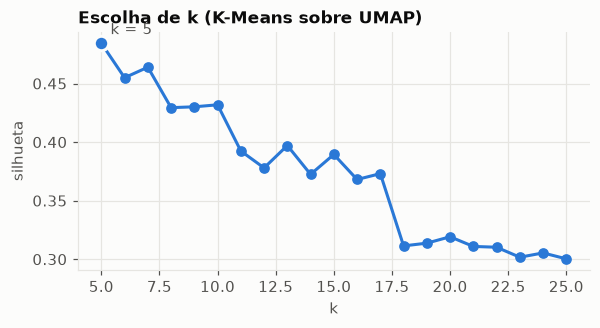

In [6]:
Z_o, lab_o, sil_o, info_o = reduz_e_agrupa(E_orig)
K = info_o["k"]
faixas["cluster"] = lab_o
dados["cluster"] = dados["track_id"].map(faixas["cluster"])
print("K-Means / HDBSCAN:", info_o)

nmi_idioma = normalized_mutual_info_score(faixas["idioma"], lab_o)
nmi_pais = normalized_mutual_info_score(dados["cc"], dados["cluster"])
print(f"NMI(cluster, idioma) = {nmi_idioma:.3f} | NMI(cluster, país) = {nmi_pais:.3f}")
if nmi_idioma > 0.5:
    print("ATENÇÃO: os clusters estão muito associados ao idioma -> dê peso à análise com tradução (seção 10).")

fig, ax = plt.subplots(figsize=(6, 2.8))
ax.plot(sil_o.index, sil_o.values, color=COR["s1"], marker="o")
ax.scatter([K], [sil_o[K]], s=90, color=COR["s1"], edgecolor=COR["fundo"], linewidth=2, zorder=3)
ax.annotate(f"k = {K}", (K, sil_o[K]), xytext=(6, 6), textcoords="offset points", color=COR["texto2"])
ax.set_xlabel("k"); ax.set_ylabel("silhueta"); ax.set_title("Escolha de k (K-Means sobre UMAP)", loc="left")
fig.savefig(PASTA_RES / "silhueta.png"); plt.show()

,cluster,n_faixas,termos,idiomas,paises,exemplos
0,0,428,"love, don, want, come, life, going, kiss, time, heart, doesn","pt 53%, es 43%, en 3%","Brasil 47%, México 28%, Espanha 20%",Happier Than Ever (Billie Eilish) · Stargazing (Myles Smith) · Ordinary (Alex Warren)
1,1,229,"love, don, say, feel, baby, better, want, need, ain, heart","en 97%, ja 3%, ko 0%","Austrália 46%, EUA 33%, Japão 10%",Shape of You (Ed Sheeran) · Redbone (Childish Gambino) · Say You Won't Let Go (James A...
2,2,194,"don, bitch, ain, nigga, shit, niggas, need, fuck, way, baby","en 92%, es 5%, ja 2%","EUA 50%, Austrália 34%, Japão 6%",Congratulations (Post Malone) · Castle on the Hill (Ed Sheeran) · HUMBLE. (Kendrick La...
3,3,161,"going, goat, don, want, love, right, day, time, hold, sound","ja 97%, en 2%, ko 1%","Japão 100%, Austrália 0%",Easy On Me (Adele) · Wherever you are (ONE OK ROCK) · My Boo (Shota Shimizu)
4,4,432,"want, don, baby, going, tell, wants, sighs, come, god, doesn","es 69%, pt 21%, en 8%","Espanha 39%, México 31%, Brasil 16%",Galway Girl (Ed Sheeran) · Symphony (feat. Zara Larsson) (Clean Bandit) · Despacito - ...


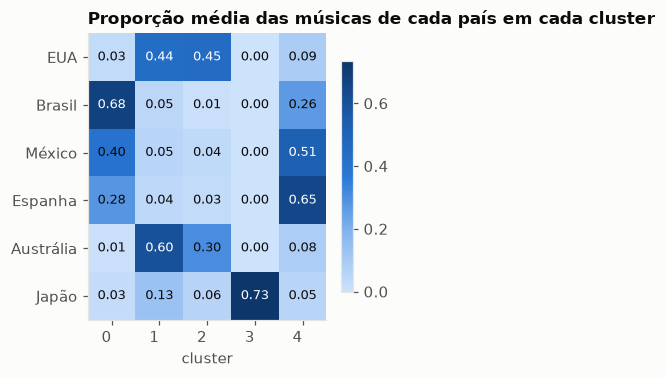

In [7]:
# interpretação: termos (c-TF-IDF, usando a tradução quando existe), tamanho, idioma e país predominantes, exemplos
texto_topicos = faixas["letra_en"].fillna(faixas["letra_limpa"])
termos = topicos_ctfidf(texto_topicos, lab_o, K)
linhas = []
for c in range(K):
    f = faixas[faixas["cluster"] == c]
    d = dados[dados["cluster"] == c]
    linhas.append({"cluster": c, "n_faixas": len(f), "termos": termos[c],
                   "idiomas": ", ".join(f"{i} {p:.0%}" for i, p in f["idioma"].value_counts(normalize=True).head(3).items()),
                   "paises": ", ".join(f"{NOMES[i]} {p:.0%}" for i, p in d["cc"].value_counts(normalize=True).head(3).items()),
                   "exemplos": " · ".join(f"{t} ({a.split('|')[0].split(',')[0].strip()})" for t, a in f[["title", "artists"]].head(3).values)})
topicos = pd.DataFrame(linhas)
with pd.option_context("display.max_colwidth", 90):
    display(topicos)

# p_{a,t} médio: como cada país se distribui pelos clusters (média dos anos)
P_pais = (dados.groupby(["cc", "year"])["cluster"].value_counts(normalize=True).unstack(fill_value=0)
               .groupby(level="cc").mean().reindex(PAISES))
fig, ax = plt.subplots(figsize=(min(1.0 + 0.5 * K, 13), 3.4))
im = plota_matriz(P_pais, "Proporção média das músicas de cada país em cada cluster", ax, SEQ, vmin=0, fmt="{:.2f}")
ax.set_xticks(range(K), range(K), rotation=0); ax.set_xlabel("cluster")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.savefig(PASTA_RES / "composicao_clusters.png"); plt.show()

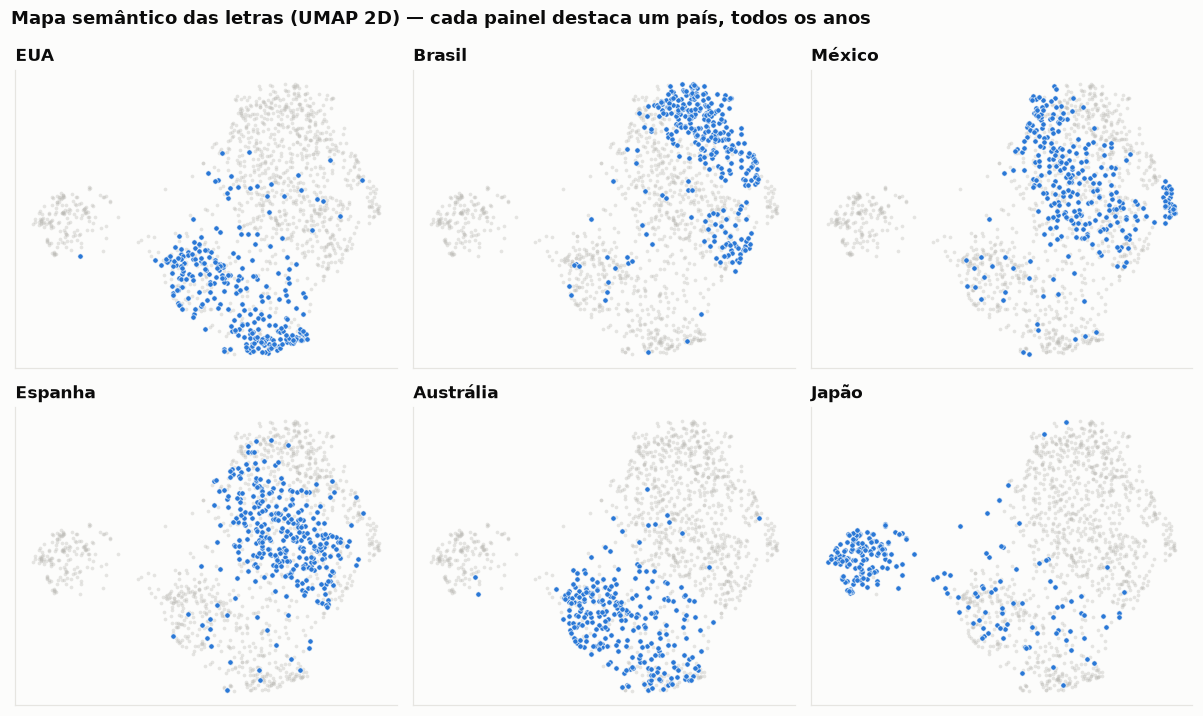

In [8]:
# mapa 2D (UMAP) — um painel por país, músicas do país em destaque sobre todas as outras
import umap
XY = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, metric="cosine", random_state=SEED).fit_transform(E_orig)
fig, axes = plt.subplots(2, 3, figsize=(11, 6.6), sharex=True, sharey=True)
for ax, cc in zip(axes.flat, PAISES):
    ix = dados.loc[dados["cc"] == cc, "track_id"].map(POS).unique()
    ax.scatter(XY[:, 0], XY[:, 1], s=6, color=COR["neutro"], alpha=0.35, linewidth=0)
    ax.scatter(XY[ix, 0], XY[ix, 1], s=12, color=COR["s1"], edgecolor=COR["fundo"], linewidth=0.4)
    ax.set_title(NOMES[cc], loc="left"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("Mapa semântico das letras (UMAP 2D) — cada painel destaca um país, todos os anos", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(PASTA_RES / "mapa_umap_paises.png"); plt.show()

## 5. Similaridade cultural global $S_t$

$S_t$ = média, sobre os 15 pares de países, de $1 - JS(p_{a,t}, p_{b,t})$ (e do cosseno entre centroides). Faixa sombreada = IC 95% por bootstrap (reamostragem de músicas dentro de cada célula). Inclinação > 0 = convergência.
Só chamamos de tendência quando o IC bootstrap da inclinação exclui 0 **e** a regressão é significativa (p < 0,05); com 9 pontos, uma tendência só no bootstrap é marcada como "fraca".
Também reportamos a tendência **sem 2017**, ano atípico (Japão com ~74% das letras em inglês; ranking reconstruído de dados diários).

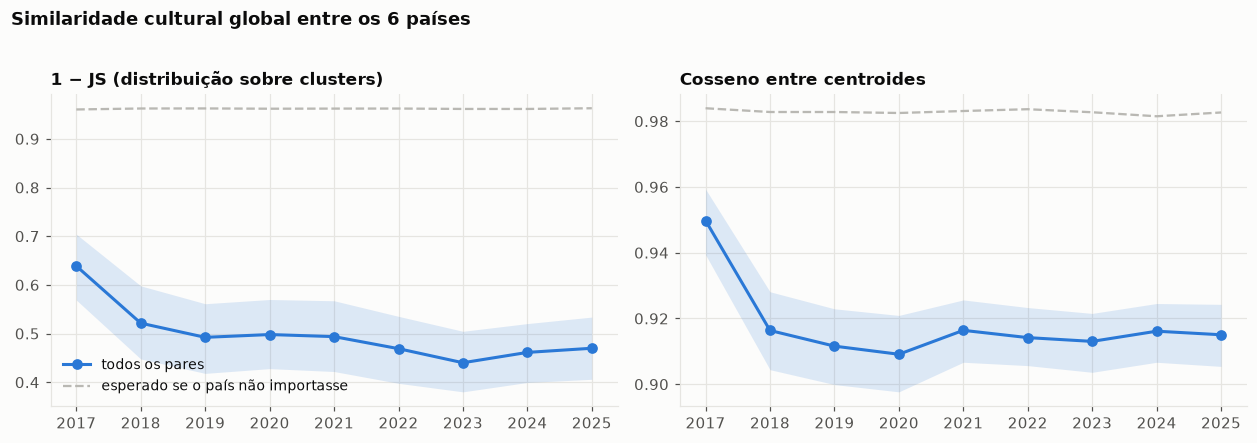

Tendência de S_t:


,serie,metrica,inclinacao_por_ano,ic95_lo,ic95_hi,p_regressao,spearman_rho,spearman_p,leitura
0,global,1−JS,-0.0165,-0.0250,-0.0077,0.0130,-0.8333,0.0053,divergência
1,global,cosseno,-0.0022,-0.0034,-0.0008,0.1772,-0.2333,0.5457,divergência fraca (só no bootstrap)
2,global sem 2017,1−JS,-0.0085,-0.0191,0.0021,0.0132,-0.7619,0.0280,sem tendência clara
3,global sem 2017,cosseno,0.0003,-0.0013,0.0019,0.5359,0.0952,0.8225,sem tendência clara


Teste de permutação por ano (p pequeno = países mais diferentes que o acaso; S_rel < 1 = abaixo do acaso):


,ano,S_js,S_js_nulo,S_js_rel,p_js,S_cos,S_cos_nulo,S_cos_rel,p_cos
0,2017,0.6387,0.9603,0.6651,0.001,0.9498,0.9839,0.9653,0.001
1,2018,0.5213,0.9623,0.5417,0.001,0.9163,0.9828,0.9324,0.001
2,2019,0.4922,0.9624,0.5114,0.001,0.9116,0.9828,0.9275,0.001
3,2020,0.4980,0.9619,0.5177,0.001,0.9091,0.9825,0.9253,0.001
4,2021,0.4937,0.9621,0.5131,0.001,0.9164,0.9831,0.9321,0.001
5,2022,0.4689,0.9622,0.4873,0.001,0.9142,0.9836,0.9294,0.001
6,2023,0.4400,0.9614,0.4577,0.001,0.9130,0.9827,0.9291,0.001
7,2024,0.4613,0.9614,0.4798,0.001,0.9161,0.9815,0.9334,0.001
8,2025,0.4698,0.9628,0.4879,0.001,0.9150,0.9827,0.9312,0.001


In [9]:
res = serie_similaridade(dados, POS, lab_o, E_orig, K)
serie_global, tend_global = resumo(res)
perm = permutacao(dados, POS, lab_o, E_orig, K)

plota_series([("todos os pares", serie_global, COR["s1"])], "Similaridade cultural global entre os 6 países",
             "serie_St.png",
             ref={"js": (perm["ano"], perm["S_js_nulo"], "esperado se o país não importasse"),
                  "cos": (perm["ano"], perm["S_cos_nulo"], "esperado se o país não importasse")})

# sensibilidade: 2017 é atípico (Japão com 74% das letras em inglês; ranking reconstruído de dados diários)
sem17 = res["pr"]["ano"] != 2017
_, tend_global_s17 = resumo(res, sem17)
print("Tendência de S_t:")
display(tabela_tendencias({"global": tend_global, "global sem 2017": tend_global_s17}))
print("Teste de permutação por ano (p pequeno = países mais diferentes que o acaso; S_rel < 1 = abaixo do acaso):")
display(perm.round(4))

## 6. Pares de países e hipóteses H1 / H2

,par,media_js,media_cos,inclinacao_js,ic95_lo,ic95_hi,leitura
0,EUA–Brasil,0.3517,0.8966,0.0085,-0.0158,0.0315,sem tendência clara
3,EUA–Austrália,0.9503,0.9882,0.0059,-0.0045,0.0170,sem tendência clara
6,Brasil–Espanha,0.8484,0.9482,0.0033,-0.0148,0.0221,sem tendência clara
5,Brasil–México,0.9156,0.9497,0.0023,-0.0113,0.0156,sem tendência clara
2,EUA–Espanha,0.3987,0.9432,0.0016,-0.0220,0.0286,sem tendência clara
1,EUA–México,0.4279,0.9338,0.0009,-0.0215,0.0254,sem tendência clara
9,México–Espanha,0.9694,0.9827,0.0004,-0.0086,0.0099,sem tendência clara
7,Brasil–Austrália,0.3040,0.8935,-0.0121,-0.0330,0.0107,sem tendência clara
4,EUA–Japão,0.3732,0.8741,-0.0213,-0.0407,-0.0016,divergência fraca (só no bootstrap)
10,México–Austrália,0.3844,0.9333,-0.0265,-0.0503,-0.0021,divergência fraca (só no bootstrap)


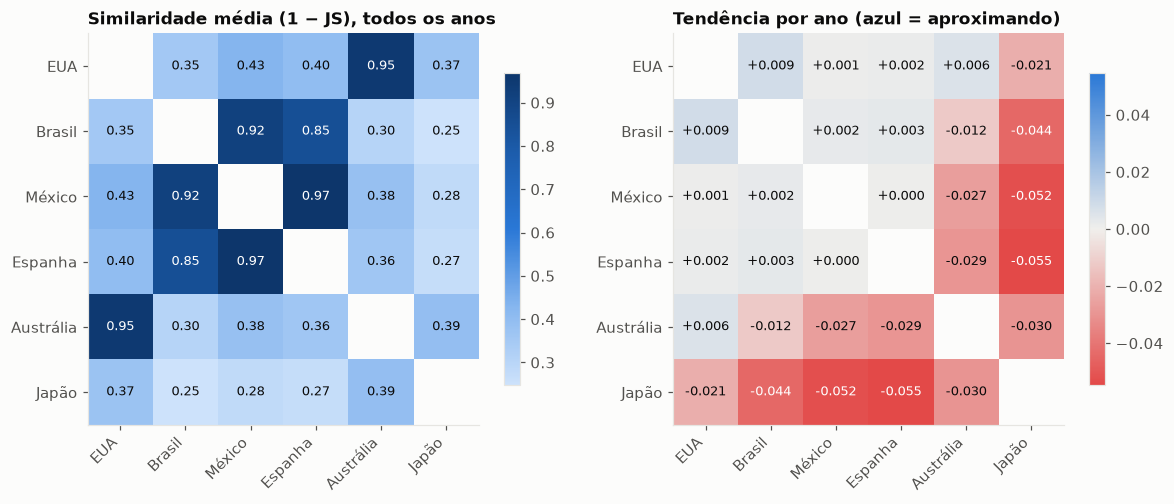

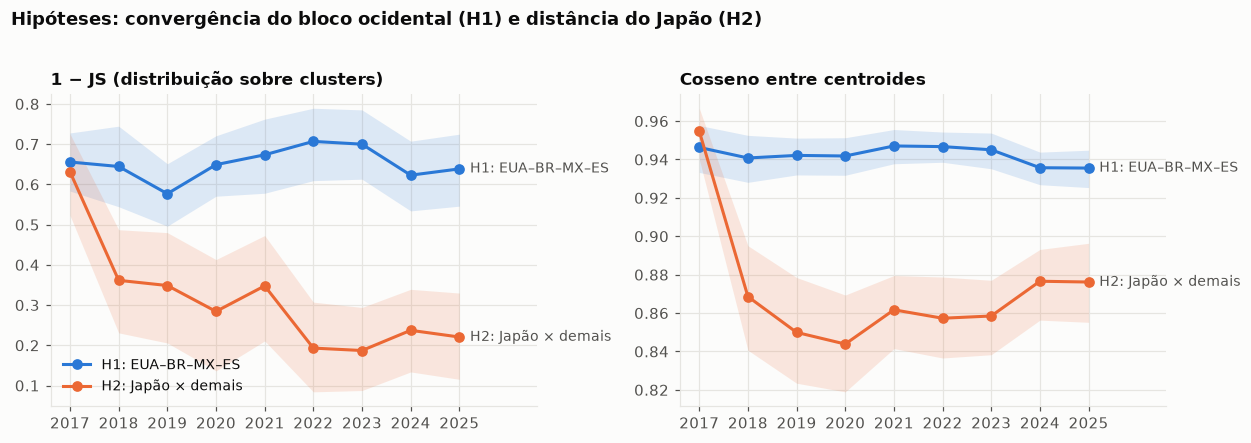

,serie,metrica,inclinacao_por_ano,ic95_lo,ic95_hi,p_regressao,spearman_rho,spearman_p,leitura
0,"H1 (pares entre EUA, BR, MX, ES)",1−JS,0.0029,-0.0076,0.0148,0.6111,0.0000,1.0000,sem tendência clara
1,"H1 (pares entre EUA, BR, MX, ES)",cosseno,-0.0008,-0.0021,0.0007,0.1814,-0.3500,0.3558,sem tendência clara
2,H1 sem 2017,1−JS,0.0045,-0.0089,0.0191,0.5365,0.0714,0.8665,sem tendência clara
3,H1 sem 2017,cosseno,-0.0007,-0.0022,0.0010,0.3413,-0.2857,0.4927,sem tendência clara
4,H2 (Japão com os demais),1−JS,-0.0405,-0.0543,-0.0257,0.0087,-0.8500,0.0037,divergência
5,H2 (Japão com os demais),cosseno,-0.0043,-0.0068,-0.0016,0.3414,0.0667,0.8647,divergência fraca (só no bootstrap)
6,H2 sem 2017,1−JS,-0.0237,-0.0416,-0.0050,0.0178,-0.7857,0.0208,divergência
7,H2 sem 2017,cosseno,0.0027,-0.0010,0.0064,0.1479,0.5238,0.1827,sem tendência clara


In [10]:
pares = res["pares_df"]
linhas = []
for (a, b), g in pares.groupby(["a", "b"], sort=False):
    m = (res["pr"]["a"] == a) & (res["pr"]["b"] == b)
    _, t = resumo(res, m)
    linhas.append({"a": a, "b": b, "par": f"{NOMES[a]}–{NOMES[b]}", "media_js": g["sim_js"].mean(), "media_cos": g["sim_cos"].mean(),
                   "inclinacao_js": t["js"]["inclinacao_por_ano"], "ic95_lo": t["js"]["ic95_lo"], "ic95_hi": t["js"]["ic95_hi"],
                   "leitura": t["js"]["leitura"]})
tend_pares = pd.DataFrame(linhas).sort_values("inclinacao_js", ascending=False)
display(tend_pares.drop(columns=["a", "b"]).round(4))

def matriz(col):
    M = pd.DataFrame(np.nan, index=PAISES, columns=PAISES)
    for r in tend_pares.itertuples():
        M.loc[r.a, r.b] = M.loc[r.b, r.a] = getattr(r, col)
    return M

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
im0 = plota_matriz(matriz("media_js"), "Similaridade média (1 − JS), todos os anos", axes[0], SEQ)
fig.colorbar(im0, ax=axes[0], shrink=0.8)
Mi = matriz("inclinacao_js"); lim = np.nanmax(np.abs(Mi.values))
im1 = plota_matriz(Mi, "Tendência por ano (azul = aproximando)", axes[1], DIV, vmin=-lim, vmax=lim, fmt="{:+.3f}")
fig.colorbar(im1, ax=axes[1], shrink=0.8)
fig.tight_layout(); fig.savefig(PASTA_RES / "pares_paises.png"); plt.show()

# hipóteses
outros = [p for p in PAISES if p not in GRUPO_H2]
s_h1, t_h1 = resumo(res, mascara_pares(res, GRUPO_H1))
s_h2, t_h2 = resumo(res, mascara_pares(res, GRUPO_H2, outros))
plota_series([("H1: EUA–BR–MX–ES", s_h1, COR["s1"]), ("H2: Japão × demais", s_h2, COR["s2"])],
             "Hipóteses: convergência do bloco ocidental (H1) e distância do Japão (H2)", "hipoteses_H1_H2.png")
_, t_h1_s17 = resumo(res, mascara_pares(res, GRUPO_H1) & sem17)
_, t_h2_s17 = resumo(res, mascara_pares(res, GRUPO_H2, outros) & sem17)
display(tabela_tendencias({"H1 (pares entre EUA, BR, MX, ES)": t_h1, "H1 sem 2017": t_h1_s17,
                           "H2 (Japão com os demais)": t_h2, "H2 sem 2017": t_h2_s17}))

## 7. Grafo de países e comunidades (Louvain)

,ano,n_comunidades,comunidades
0,2017,2,Brasil + México + Espanha | EUA + Austrália + Japão
1,2018,2,Brasil + México + Espanha + Japão | EUA + Austrália
2,2019,2,Brasil + México + Espanha + Japão | EUA + Austrália
3,2020,3,Brasil + México + Espanha | EUA + Austrália | Japão
4,2021,2,Brasil + México + Espanha | EUA + Austrália + Japão
5,2022,2,Brasil + México + Espanha | EUA + Austrália + Japão
6,2023,2,Brasil + México + Espanha | EUA + Austrália + Japão
7,2024,2,Brasil + México + Espanha | EUA + Austrália + Japão
8,2025,2,Brasil + México + Espanha | EUA + Austrália + Japão


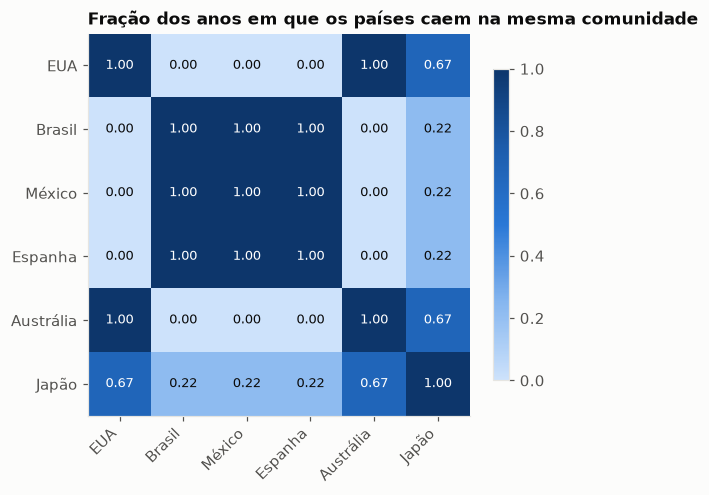

In [11]:
com_ano, junto = comunidades(pares)
with pd.option_context("display.max_colwidth", 120):
    display(com_ano)
fig, ax = plt.subplots(figsize=(5.6, 4.6))
im = plota_matriz(junto, "Fração dos anos em que os países caem na mesma comunidade", ax, SEQ, vmin=0, vmax=1)
fig.colorbar(im, ax=ax, shrink=0.8)
fig.savefig(PASTA_RES / "comunidades.png"); plt.show()

## 8. Controle: músicas compartilhadas × exclusivas

Uma música é *compartilhada* num ano se aparece no top 40 de 2+ países naquele ano (comparando por título + artista principal, não por `track_id`, que muda entre versões). Se a convergência some quando só as exclusivas são usadas, ela é explicada pelos hits globais.

,pct_compartilhadas,musicas_em_2mais,musicas_em_4mais
year,,,
2017,52.1,49,6
2018,36.4,39,3
2019,35.8,38,3
2020,31.2,32,3
2021,30.5,34,1
2022,27.9,31,1
2023,25.8,30,1
2024,22.9,27,0
2025,26.2,29,1


músicas exclusivas por célula:


year,2017,2018,2019,2020,2021,2022,2023,2024,2025
cc,,,,,,,,,
au,12,14,14,16,17,23,22,19,16
br,34,38,37,35,38,39,39,39,38
es,12,23,26,29,28,27,30,34,35
jp,23,38,38,39,40,39,40,40,38
mx,12,23,24,27,27,25,27,34,36
us,21,16,15,19,16,20,20,19,14


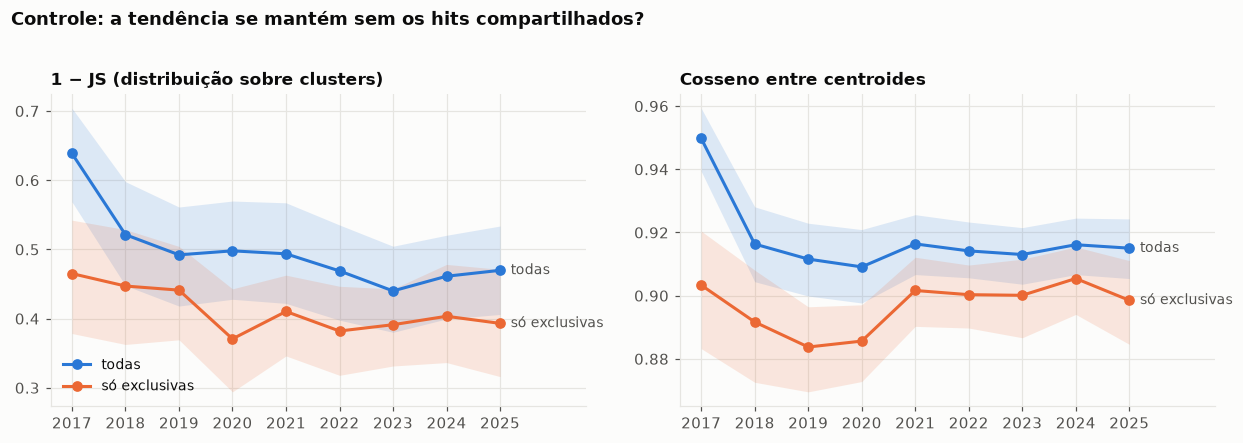

,serie,metrica,inclinacao_por_ano,ic95_lo,ic95_hi,p_regressao,spearman_rho,spearman_p,leitura
0,todas,1−JS,-0.0165,-0.0250,-0.0077,0.0130,-0.8333,0.0053,divergência
1,todas,cosseno,-0.0022,-0.0034,-0.0008,0.1772,-0.2333,0.5457,divergência fraca (só no bootstrap)
2,só exclusivas,1−JS,-0.0085,-0.0180,0.0015,0.0299,-0.6000,0.0876,sem tendência clara
3,só exclusivas,cosseno,0.0012,-0.0007,0.0032,0.2787,0.2333,0.5457,sem tendência clara


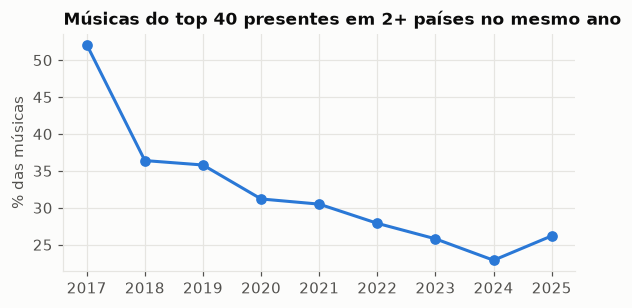

In [12]:
n_paises = dados.groupby(["year", "chave"])["cc"].transform("nunique")
dados["compartilhada"] = n_paises >= 2
comp = dados.groupby("year").agg(pct_compartilhadas=("compartilhada", "mean"),
                                 musicas_em_2mais=("chave", lambda s: s[dados.loc[s.index, "compartilhada"]].nunique()))
comp["musicas_em_4mais"] = dados[n_paises >= 4].groupby("year")["chave"].nunique().reindex(comp.index, fill_value=0)
comp["pct_compartilhadas"] = (comp["pct_compartilhadas"] * 100).round(1)
display(comp)

excl = dados[~dados["compartilhada"]]
excl = excl[excl.groupby(["cc", "year"])["track_id"].transform("size") >= MIN_CELULA]
print("músicas exclusivas por célula:")
display(excl.groupby(["cc", "year"]).size().unstack())
res_excl = serie_similaridade(excl, POS, lab_o, E_orig, K)
serie_excl, tend_excl = resumo(res_excl)
plota_series([("todas", serie_global, COR["s1"]), ("só exclusivas", serie_excl, COR["s2"])],
             "Controle: a tendência se mantém sem os hits compartilhados?", "controle_exclusivas.png")
display(tabela_tendencias({"todas": tend_global, "só exclusivas": tend_excl}))

fig, ax = plt.subplots(figsize=(6, 2.8))
ax.plot(comp.index, comp["pct_compartilhadas"], color=COR["s1"], marker="o")
ax.set_xticks(comp.index); ax.set_ylabel("% das músicas")
ax.set_title("Músicas do top 40 presentes em 2+ países no mesmo ano", loc="left")
fig.savefig(PASTA_RES / "pct_compartilhadas.png"); plt.show()

## 9. Estratificação por idioma

Composição de idiomas por célula. Mudanças de composição (ex.: mais músicas em inglês no Japão) podem, sozinhas, mover $S_t$.

In [13]:
comp_idioma = (pd.crosstab([dados["cc"], dados["year"]], dados["idioma"], normalize="index") * 100).round(0)
display(comp_idioma)

idioma      en     es    ja   ko  outro    pt
cc year                                      
au 2017   98.0    2.0   0.0  0.0    0.0   0.0
   2018  100.0    0.0   0.0  0.0    0.0   0.0
   2019  100.0    0.0   0.0  0.0    0.0   0.0
   2020  100.0    0.0   0.0  0.0    0.0   0.0
   2021  100.0    0.0   0.0  0.0    0.0   0.0
   2022  100.0    0.0   0.0  0.0    0.0   0.0
   2023  100.0    0.0   0.0  0.0    0.0   0.0
   2024  100.0    0.0   0.0  0.0    0.0   0.0
   2025  100.0    0.0   0.0  0.0    0.0   0.0
br 2017   15.0    3.0   0.0  0.0    0.0  82.0
   2018    5.0    3.0   0.0  0.0    0.0  92.0
   2019    8.0    2.0   0.0  0.0    0.0  90.0
   2020   12.0    2.0   0.0  0.0    0.0  85.0
   2021    5.0    0.0   0.0  0.0    0.0  95.0
   2022    2.0    0.0   0.0  0.0    0.0  98.0
   2023    2.0    0.0   0.0  0.0    0.0  98.0
   2024    2.0    0.0   0.0  0.0    0.0  98.0
   2025    5.0    0.0   0.0  0.0    0.0  95.0
es 2017   20.0   80.0   0.0  0.0    0.0   0.0
   2018   20.0   80.0   0.0  0.0    0.0   0.0
   2019    8.0   92.0   0.0  0.0    0.0   0.0
   2020    8.0   92.0   0.0  0.0    0.0   0.0
   2021    5.0   95.0   0.0  0.0    0.0   0.0
   2022    0.0  100.0   0.0  0.0    0.0   0.0
   2023    0.0  100.0   0.0  0.0    0.0   0.0
   2024    2.0   95.0   0.0  0.0    2.0   0.0
   2025    2.0   98.0   0.0  0.0    0.0   0.0
jp 2017   74.0    3.0  21.0  3.0    0.0   0.0
   2018   22.0    0.0  75.0  2.0    0.0   0.0
   2019    8.0    0.0  92.0  0.0    0.0   0.0
   2020    8.0    0.0  92.0  0.0    0.0   0.0
   2021    8.0    0.0  85.0  2.0    5.0   0.0
   2022    8.0    0.0  92.0  0.0    0.0   0.0
   2023   12.0    0.0  88.0  0.0    0.0   0.0
   2024    8.0    0.0  90.0  0.0    2.0   0.0
   2025   12.0    0.0  88.0  0.0    0.0   0.0
mx 2017   18.0   82.0   0.0  0.0    0.0   0.0
   2018   12.0   88.0   0.0  0.0    0.0   0.0
   2019   20.0   80.0   0.0  0.0    0.0   0.0
   2020   12.0   88.0   0.0  0.0    0.0   0.0
   2021    5.0   95.0   0.0  0.0    0.0   0.0
   2022    2.0   98.0   0.0  0.0    0.0   0.0
   2023    2.0   98.0   0.0  0.0    0.0   0.0
   2024    0.0  100.0   0.0  0.0    0.0   0.0
   2025    0.0  100.0   0.0  0.0    0.0   0.0
us 2017   98.0    2.0   0.0  0.0    0.0   0.0
   2018   98.0    2.0   0.0  0.0    0.0   0.0
   2019  100.0    0.0   0.0  0.0    0.0   0.0
   2020  100.0    0.0   0.0  0.0    0.0   0.0
   2021   95.0    5.0   0.0  0.0    0.0   0.0
   2022   92.0    8.0   0.0  0.0    0.0   0.0
   2023   95.0    5.0   0.0  0.0    0.0   0.0
   2024  100.0    0.0   0.0  0.0    0.0   0.0
   2025   98.0    2.0   0.0  0.0    0.0   0.0

## 10. Robustez: letras traduzidas para o inglês

Refaz embeddings, clusters e as tendências usando `letra_en`, **no mesmo conjunto de faixas e países** para as duas versões (original × traduzida). Se uma conclusão só aparece com a letra original, ela reflete **idioma**, não conteúdo.
Só entram países com tradução suficiente (`MIN_CELULA`) em todos os anos — se o conjunto de pares mudasse entre anos, a tendência ficaria contaminada.

cobertura da tradução por célula (%):


year,2017,2018,2019,2020,2021,2022,2023,2024,2025
cc,,,,,,,,,
au,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
br,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
es,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
jp,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
mx,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
us,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0


países na comparação: ['EUA', 'Brasil', 'México', 'Espanha', 'Austrália', 'Japão']
[traducao_en] 1444 embeddings lidos do cache dados/embeddings/sentence_transformers_LaBSE__traducao_en.npz


original: k=5 | silhueta=0.484 | NMI(cluster, idioma) = 0.519


traduzida: k=5 | silhueta=0.416 | NMI(cluster, idioma) = 0.295


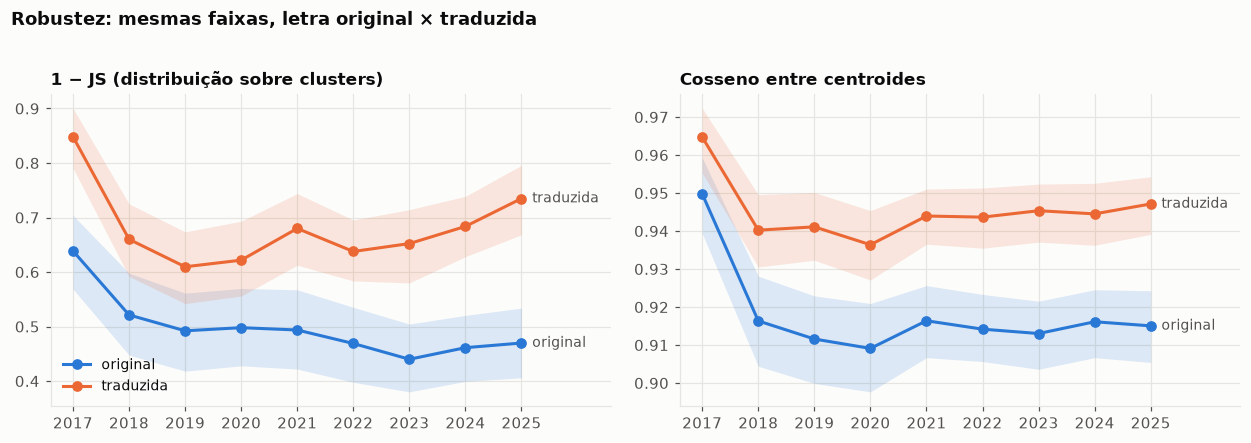

,serie,metrica,inclinacao_por_ano,ic95_lo,ic95_hi,p_regressao,spearman_rho,spearman_p,leitura
0,original: global,1−JS,-0.0165,-0.0250,-0.0077,0.0130,-0.8333,0.0053,divergência
1,original: global,cosseno,-0.0022,-0.0034,-0.0008,0.1772,-0.2333,0.5457,divergência fraca (só no bootstrap)
2,original: global sem 2017,1−JS,-0.0085,-0.0191,0.0021,0.0132,-0.7619,0.0280,sem tendência clara
3,original: global sem 2017,cosseno,0.0003,-0.0013,0.0019,0.5359,0.0952,0.8225,sem tendência clara
4,original: H1,1−JS,0.0029,-0.0076,0.0148,0.6111,0.0000,1.0000,sem tendência clara
5,original: H1,cosseno,-0.0008,-0.0021,0.0007,0.1814,-0.3500,0.3558,sem tendência clara
6,original: H1 sem 2017,1−JS,0.0045,-0.0089,0.0191,0.5365,0.0714,0.8665,sem tendência clara
7,original: H1 sem 2017,cosseno,-0.0007,-0.0022,0.0010,0.3413,-0.2857,0.4927,sem tendência clara
8,original: H2,1−JS,-0.0405,-0.0543,-0.0257,0.0087,-0.8500,0.0037,divergência
9,original: H2,cosseno,-0.0043,-0.0068,-0.0016,0.3414,0.0667,0.8647,divergência fraca (só no bootstrap)


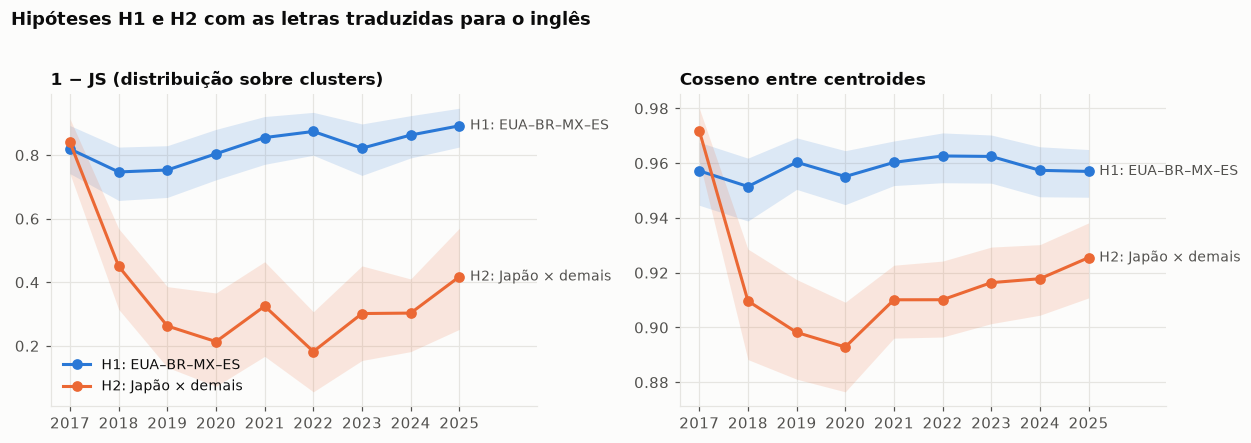

concordância das séries (js): Spearman rho = 0.17 (p = 0.668)
concordância das séries (cos): Spearman rho = 0.50 (p = 0.170)


In [14]:
tem = faixas["letra_en"].notna()
cob = dados.assign(t=dados["track_id"].map(tem)).groupby(["cc", "year"])["t"].mean().unstack()
print("cobertura da tradução por célula (%):")
display((cob * 100).round(0))

rob = {}
if tem.sum() < 200:
    print(f"só {tem.sum()} faixas traduzidas — rode de novo quando a tradução estiver completa.")
else:
    fx = faixas[tem]
    pos_sub = {t: i for i, t in enumerate(fx.index)}
    d_sub = dados[dados["track_id"].isin(fx.index)]
    d_sub = d_sub[d_sub.groupby(["cc", "year"])["track_id"].transform("size") >= MIN_CELULA]
    # só países com todos os anos: se o conjunto de pares muda entre anos, a tendência de S_t fica contaminada
    n_anos = dados["year"].nunique()
    completos = [c for c in PAISES if d_sub.loc[d_sub["cc"] == c, "year"].nunique() == n_anos]
    fora = [c for c in PAISES if c not in completos]
    d_sub = d_sub[d_sub["cc"].isin(completos)]
    print("países na comparação:", [NOMES[c] for c in completos])
    if fora:
        print("fora por falta de tradução em algum ano:", [NOMES[c] for c in fora], "-> rode de novo quando a tradução terminar")
    E_en = gera_embeddings(fx["letra_en"], "traducao_en")
    excl_sub = d_sub[~d_sub["compartilhada"]]
    excl_sub = excl_sub[excl_sub.groupby(["cc", "year"])["track_id"].transform("size") >= MIN_CELULA]
    outros_sub = [p for p in completos if p not in GRUPO_H2]
    for nome, E_ in [("original", E_orig[[POS[t] for t in fx.index]]), ("traduzida", E_en)]:
        _, lab, _, info = reduz_e_agrupa(E_)
        r = serie_similaridade(d_sub, pos_sub, lab, E_, info["k"])
        s17 = r["pr"]["ano"] != 2017
        s, t = resumo(r)
        rob[nome] = {"serie": s, "tend": t, "info": info, "res": r,
                     "nmi_idioma": normalized_mutual_info_score(fx["idioma"], lab),
                     "tend_s17": resumo(r, s17)[1]}
        if set(GRUPO_H1) <= set(completos):
            rob[nome]["h1"] = resumo(r, mascara_pares(r, GRUPO_H1))
            rob[nome]["h1_s17"] = resumo(r, mascara_pares(r, GRUPO_H1) & s17)[1]
        if set(GRUPO_H2) <= set(completos):
            rob[nome]["h2"] = resumo(r, mascara_pares(r, GRUPO_H2, outros_sub))
            rob[nome]["h2_s17"] = resumo(r, mascara_pares(r, GRUPO_H2, outros_sub) & s17)[1]
        r_ex = serie_similaridade(excl_sub, pos_sub, lab, E_, info["k"])
        rob[nome]["excl"] = resumo(r_ex)[1]
        # controle das hipóteses: só músicas exclusivas de cada país
        if set(GRUPO_H1) <= set(completos):
            rob[nome]["h1_excl"] = resumo(r_ex, mascara_pares(r_ex, GRUPO_H1))[1]
        if set(GRUPO_H2) <= set(completos):
            rob[nome]["h2_excl"] = resumo(r_ex, mascara_pares(r_ex, GRUPO_H2, outros_sub))[1]
        print(f"{nome}: k={info['k']} | silhueta={info['silhueta']} | NMI(cluster, idioma) = {rob[nome]['nmi_idioma']:.3f}")
    plota_series([("original", rob["original"]["serie"], COR["s1"]), ("traduzida", rob["traduzida"]["serie"], COR["s2"])],
                 "Robustez: mesmas faixas, letra original × traduzida", "robustez_traducao.png")
    tabs = {}
    for nome in ["original", "traduzida"]:
        v = rob[nome]
        tabs[f"{nome}: global"] = v["tend"]
        tabs[f"{nome}: global sem 2017"] = v["tend_s17"]
        if "h1" in v:
            tabs[f"{nome}: H1"] = v["h1"][1]; tabs[f"{nome}: H1 sem 2017"] = v["h1_s17"]
        if "h2" in v:
            tabs[f"{nome}: H2"] = v["h2"][1]; tabs[f"{nome}: H2 sem 2017"] = v["h2_s17"]
        tabs[f"{nome}: só exclusivas"] = v["excl"]
        if "h1_excl" in v:
            tabs[f"{nome}: H1 só exclusivas"] = v["h1_excl"]
        if "h2_excl" in v:
            tabs[f"{nome}: H2 só exclusivas"] = v["h2_excl"]
    tab_rob = tabela_tendencias(tabs)
    display(tab_rob)
    if "h1" in rob["traduzida"] and "h2" in rob["traduzida"]:
        plota_series([("H1: EUA–BR–MX–ES", rob["traduzida"]["h1"][0], COR["s1"]),
                      ("H2: Japão × demais", rob["traduzida"]["h2"][0], COR["s2"])],
                     "Hipóteses H1 e H2 com as letras traduzidas para o inglês", "hipoteses_H1_H2_traduzida.png")
    for met in ["js", "cos"]:
        rho, p = spearmanr(rob["original"]["serie"][met], rob["traduzida"]["serie"][met])
        print(f"concordância das séries ({met}): Spearman rho = {rho:.2f} (p = {p:.3f})")

## 11. Salvar resultados e resumo

In [15]:
pares.to_csv(PASTA_RES / "similaridade_pares.csv", index=False)
serie_global.to_csv(PASTA_RES / "serie_St.csv", index=False)
perm.to_csv(PASTA_RES / "permutacao.csv", index=False)
tend_pares.to_csv(PASTA_RES / "tendencia_pares.csv", index=False)
com_ano.to_csv(PASTA_RES / "comunidades_louvain.csv", index=False)
topicos.to_csv(PASTA_RES / "clusters_topicos.csv", index=False)
comp.to_csv(PASTA_RES / "compartilhadas.csv")
todas_t = {"global": tend_global, "global_sem_2017": tend_global_s17, "H1": t_h1, "H1_sem_2017": t_h1_s17,
           "H2": t_h2, "H2_sem_2017": t_h2_s17, "so_exclusivas": tend_excl}
tab_todas = tabela_tendencias(todas_t)
if rob:
    tab_todas = pd.concat([tab_todas, tab_rob.assign(serie="traducao | " + tab_rob["serie"])], ignore_index=True)
tab_todas.to_csv(PASTA_RES / "tendencias.csv", index=False)
# atribuição de cluster por música (sem letra)
dados[["cc", "year", "track_id", "title", "artists", "idioma", "cluster", "compartilhada"]].to_csv(
    PASTA_RES / "musicas_clusters.csv", index=False)

def fmt(t):
    return (f"{t['inclinacao_por_ano']:+.4f}/ano [IC95% {t['ic95_lo']:+.4f}, {t['ic95_hi']:+.4f}] "
            f"p_reg={t['p_regressao']:.3f} -> {t['leitura']}")

print(f"Modelo: {MODELO} | k = {K} | {len(faixas)} faixas | células excluídas: {EXCLUIR or 'nenhuma'}")
print(f"NMI(cluster, idioma) = {nmi_idioma:.2f}")
print(f"S_t (1−JS) global ........ {fmt(tend_global['js'])}")
print(f"S_t (cosseno) global ..... {fmt(tend_global['cos'])}")
print(f"S_t (1−JS) sem 2017 ...... {fmt(tend_global_s17['js'])}")
print(f"H1 EUA–BR–MX–ES (1−JS) ... {fmt(t_h1['js'])}")
print(f"H1 sem 2017 (1−JS) ....... {fmt(t_h1_s17['js'])}")
print(f"H2 Japão × demais (1−JS) . {fmt(t_h2['js'])}")
print(f"H2 sem 2017 (1−JS) ....... {fmt(t_h2_s17['js'])}")
print(f"Só exclusivas (1−JS) ..... {fmt(tend_excl['js'])}")
for k, v in rob.items():
    print(f"\n[{k}] NMI(cluster, idioma) = {v['nmi_idioma']:.2f}")
    print(f"  S_t global (1−JS) ...... {fmt(v['tend']['js'])}")
    print(f"  S_t global (cosseno) ... {fmt(v['tend']['cos'])}")
    print(f"  S_t sem 2017 (1−JS) .... {fmt(v['tend_s17']['js'])}")
    if "h1" in v:
        print(f"  H1 (1−JS) .............. {fmt(v['h1'][1]['js'])}")
        print(f"  H1 sem 2017 (1−JS) ..... {fmt(v['h1_s17']['js'])}")
    if "h2" in v:
        print(f"  H2 (1−JS) .............. {fmt(v['h2'][1]['js'])}")
        print(f"  H2 sem 2017 (1−JS) ..... {fmt(v['h2_s17']['js'])}")
    print(f"  Só exclusivas (1−JS) ... {fmt(v['excl']['js'])}")
    if "h1_excl" in v:
        print(f"  H1 só exclusivas ....... {fmt(v['h1_excl']['js'])}")
    if "h2_excl" in v:
        print(f"  H2 só exclusivas ....... {fmt(v['h2_excl']['js'])}")
print(f"\nPermutação: países mais distintos que o acaso (p<0,05) em {(perm['p_js'] < 0.05).sum()} de {len(perm)} anos (1−JS)")
print("Arquivos em", PASTA_RES.resolve())

Modelo: sentence-transformers/LaBSE | k = 5 | 1444 faixas | células excluídas: nenhuma
NMI(cluster, idioma) = 0.52
S_t (1−JS) global ........ -0.0165/ano [IC95% -0.0250, -0.0077] p_reg=0.013 -> divergência
S_t (cosseno) global ..... -0.0022/ano [IC95% -0.0034, -0.0008] p_reg=0.177 -> divergência fraca (só no bootstrap)
S_t (1−JS) sem 2017 ...... -0.0085/ano [IC95% -0.0191, +0.0021] p_reg=0.013 -> sem tendência clara
H1 EUA–BR–MX–ES (1−JS) ... +0.0029/ano [IC95% -0.0076, +0.0148] p_reg=0.611 -> sem tendência clara
H1 sem 2017 (1−JS) ....... +0.0045/ano [IC95% -0.0089, +0.0191] p_reg=0.536 -> sem tendência clara
H2 Japão × demais (1−JS) . -0.0405/ano [IC95% -0.0543, -0.0257] p_reg=0.009 -> divergência
H2 sem 2017 (1−JS) ....... -0.0237/ano [IC95% -0.0416, -0.0050] p_reg=0.018 -> divergência
Só exclusivas (1−JS) ..... -0.0085/ano [IC95% -0.0180, +0.0015] p_reg=0.030 -> sem tendência clara

[original] NMI(cluster, idioma) = 0.52
  S_t global (1−JS) ...... -0.0165/ano [IC95% -0.0250, -0.007